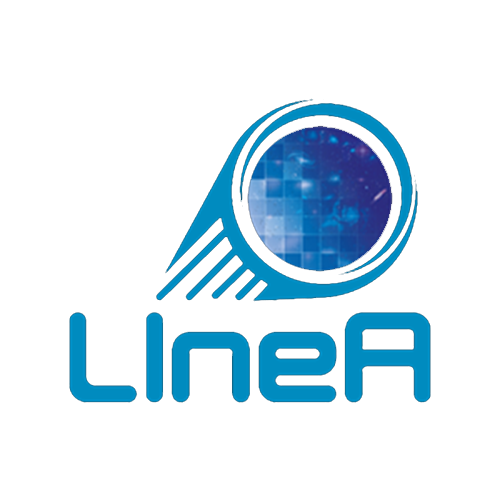

# High-Performance Computing (HPC) Applied to Astronomy

*Practical demonstration of the basic features of Dask applied to the processing of large-scale astronomical data.*

**Author:** Luigi Silva  
**Email:** luigi.silva@linea.org.br  
**Last checked:** 11/04/2026

# Introduction

This notebook is part of the course **High-Performance Computing (HPC) Applied to Astronomy**, offered by LIneA.

The goal is to present, in a practical and intuitive way, how to use **Dask** to manipulate and visualize large-scale astronomical data in a **parallel and efficient** manner, highlighting its integration with the Python scientific ecosystem (pandas, NumPy, scikit-learn, etc.).

## Scalability and didactic purpose

For **didactic and accessibility purposes**, we will work with a **0.1% sample of the DES DR2 catalog**, containing **691,456 objects**.
This sample was pre-processed and partitioned into 10 Parquet files, allowing the notebook to be run on any computer — including by participants who do not yet have access to LIneA's HPC environment.

The **full DES DR2 catalog**, in turn, contains **691,483,608 objects** and requires **distributed execution on an HPC cluster** to be handled efficiently.
The same operations demonstrated in this notebook — reading, manipulation, and visualization — can be applied **without conceptual changes** to the full catalog.

For those with access to LIneA's HPC environment, we included an extra cell in the data reading section that demonstrates **how to read the full DES DR2 in [HATS](https://hats.readthedocs.io/en/latest/) format directly from the Lustre file system via [LSDB](https://docs.lsdb.io/en/latest/) + [Dask](https://www.dask.org/)**, taking advantage of the cluster's parallelization and high-availability resources.

## Processing and data in LIneA's HPC environment

In LIneA's HPC environment, astronomical catalogs are stored in the **Lustre** parallel file system, which is accessible simultaneously by all processing nodes through an **Infiniband network of about 100 Gb/s**.

This architecture ensures high availability and fast access to the data, allowing processing to take place **“close to the data”**, without the need to transfer large volumes over the network.

Tools such as Dask take advantage of this infrastructure by automatically distributing tasks among the cluster nodes, which read and write directly on Lustre.
In this way, the environment illustrates a fundamental principle in HPC: in large-scale scientific processing, it is the processing that goes to the data — and not the other way around.

## Best practices when using HPC clusters

Before creating your Dask cluster, it is essential to know **the rules and limitations of the HPC environment in which you are running the code**.
Each infrastructure has **its own configuration parameters**, such as account, partition (queue), maximum execution time, number of CPUs, and memory limits.

It is always recommended to:
- **Consult the cluster's official documentation** before starting execution;
- **Use appropriate queues and accounts** for your project group;
- **Avoid overloading the system**, limiting the number of workers and the execution time to what is necessary;
- **Respect resource usage policies**, including limits on simultaneous jobs and maximum time per user;
- **Properly shut down the Client and the Cluster at the end of the session**, releasing the allocated resources for other users.

📘 For the **Apollo Cluster (LIneA)**, the complete documentation is available at:
👉 https://docs.linea.org.br/processamento/apollo/index.html

## What will be covered

Throughout the notebook, you will:

- Create and configure a **Dask cluster** (both local and via **SLURM**);
- Read and inspect **Parquet files** containing the **DES DR2** sample;
- Perform manipulation operations, such as the calculation of **photometric colors**;
- Generate interactive and scalable visualizations with **Datashader + HoloViews + Dask**.

The focus is to demonstrate how Dask maintains a **familiar interface (similar to pandas)**, but with **distributed and scalable execution**, fundamental characteristics for dealing with the **large data volumes of LSST and other modern surveys**.

# Environment Setup

### Objectives
- Create a **Conda environment**;
- **make the Conda environment's kernel available** in Jupyter.

## Environment Setup — LIneA Open OnDemand
Open OnDemand (https://ondemand.linea.org.br/) allows, among other things, access to JupyterLab inside LIneA's HPC environment (Apollo cluster). This way, you can have access to the full power of the cluster and its nodes. To access it, however, you need to justify the need for access to the HPC environment. Contact the helpdesk (helpdesk@linea.org.br) for this. It is also essential to read all the documentation at https://docs.linea.org.br/processamento/apollo/index.html.

On the [Open OnDemand](https://ondemand.linea.org.br/) home page, click: Clusters → LIneA Shell Access.

### Create and configure the environment
```bash
conda create -p /scripts/$USER/LSST_LATAM/lsst_latam_env python=3.12
conda activate $SCRIPTS/LSST_LATAM/lsst_latam_env
conda install -c conda-forge ipykernel dask distributed dask-jobqueue bokeh holoviews geoviews datashader cartopy pandas numpy hats==0.6.7 lsdb==0.6.7 -y
```

### Register the kernel
```bash
export JUPYTER_PATH=$SCRATCH/.local
python -m ipykernel install --prefix=$JUPYTER_PATH --name '3rd_lsst_latam'
```

The kernel will appear in the Jupyter Notebook interface on OnDemand.

📘 Detailed instructions: https://docs.linea.org.br/processamento/uso/openondemand.html

## Haven't registered yet?
If you have not yet registered with LIneA to access our platforms, we invite you to register! 

https://docs.linea.org.br/primeiros_passos.html

# Cluster Creation and Client Connection

**Dask** uses the idea of *Cluster + Client* to execute tasks in a parallel and distributed manner.

- The **Cluster** is the set of *workers* (processes or nodes) that do the heavy lifting;
- The **Client** is the control point that allows you to send and monitor tasks on the cluster.

In this section, we will see two ways to create a cluster:

1. **Local Cluster** — ideal for testing and for notebooks running on a personal machine or on an interactive node;
2. **SLURM Cluster** — used in HPC environments, where resources are managed by the job scheduler (as in the case of Apollo/LIneA).

## Defining the type of cluster to be created

In [1]:
%%time

# ==========================================================
# ⚙️ Define the cluster type
# ==========================================================
# Choose between "local" and "slurm"
# "local" → runs on your machine or interactive node
# "slurm" → uses the job scheduler (e.g., Apollo/LIneA)

CLUSTER_TYPE = "slurm"  # change to "slurm" if you are in an HPC environment

CPU times: user 2 μs, sys: 0 ns, total: 2 μs
Wall time: 3.58 μs


## SLURM Cluster

In **High-Performance Computing (HPC)** environments, such as **LIneA's Apollo**, computational resources (CPU, memory, execution time, etc.) are managed by a **job scheduler** — in our case, **SLURM** (*Simple Linux Utility for Resource Management*).

Dask has a direct integration with SLURM through the `SLURMCluster` class, available in the `dask_jobqueue` module. This class allows Dask to **dynamically request and release resources** on the HPC cluster.

In practical terms:
- Each Dask *worker* is submitted as a **SLURM job**, which means that SLURM reserves for it the exact amount of **cores, memory, and execution time** specified;
- Dask communicates with SLURM to **submit, monitor, and terminate** these jobs as needed;
- In this way, Dask can **scale automatically** (increase or decrease) the number of active *workers* according to the workload — without the user having to manually submit `sbatch`.

`SLURMCluster` is, therefore, a bridge between the **Python ecosystem** and the **HPC resource manager**, allowing the same Dask code run on a laptop to also work efficiently on a supercomputer.

> ⚠️ **Attention!**
>
> Before creating your cluster, it is **essential to read the official documentation** of the environment in which you are running Dask.  
> Each HPC infrastructure has **its own valid combinations of `account`, `partition` (queue)** and **resource** limits (memory, time, number of CPUs, etc.).
>
> Always consult:
> - The cluster documentation to check **which queues and accounts you can use**;
> - The **best practices for resource usage**, avoiding overload or misuse;
> - The **maximum execution time policies** and **per-user limits**.
>
> 📘 For the **Apollo Cluster (LIneA)**, the complete documentation is available at:  
> 👉 [https://docs.linea.org.br/processamento/apollo/index.html](https://docs.linea.org.br/processamento/apollo/index.html)

In [2]:
%%time

# ==========================================================
# 🛰️ Cluster SLURM
# ==========================================================
# This example shows how to set up a Dask cluster
# integrated with SLURM, very useful in HPC environments.

if CLUSTER_TYPE == "slurm":
    from dask_jobqueue import SLURMCluster
    from dask.distributed import Client
    
    # Creating the SLURM cluster
    cluster = SLURMCluster(
        n_workers=5,              # initial number of workers
        queue="cpu_dev",              # partition (queue) in SLURM
        account="hpc-public",     # project account
        cores=8,                  # cores per worker
        memory="16GB",            # memory per worker
        processes=1,              # processes per worker
        interface="ib0",          # Infiniband network interface
        walltime="00:30:00",      # maximum time per job
        job_extra_directives=[
            "--propagate"         # ensures inheritance of environment variables
        ]
    )
    
    # ==========================================================
    # Automatic scaling with adapt()
    # ==========================================================
    # The adapt() method makes Dask dynamically adjust the number of jobs
    # based on the workload. If there are many pending tasks,
    # the cluster allocates new workers; when the tasks finish,
    # it automatically reduces the number of jobs.
    #
    # Here we set the minimum and maximum limits of active jobs.
    cluster.adapt(minimum_jobs=5, maximum_jobs=10)
    
    # ==========================================================
    # Manual scaling with scale()
    # ==========================================================
    # Alternatively, we could manually control the cluster size,
    # fixing an exact number of running jobs (workers).
    #
    # 👉 Use this option when you want a stable number of workers
    #    throughout the processing.
    #
    # Example (commented out so it doesn't conflict with adapt()):
    # cluster.scale(jobs=5)

    # Connect the Client to the cluster
    client = Client(cluster)

    # (Optional) Wait for the workers to start up
    client.wait_for_workers(5, timeout=10)

CPU times: user 764 ms, sys: 96.1 ms, total: 860 ms
Wall time: 5.28 s


## Displaying Client Information

After creating the cluster and connecting the client, we can check the connection status.  
Dask will display a link to the **Dashboard**, where it is possible to monitor CPU usage, memory, tasks, and workers in real time.

In [3]:
%%time

# ==========================================================
# 📊 Displaying Client and Dashboard information
# ==========================================================
print("✅ Client connected successfully!")
print(f"Dask Dashboard available at: {client.dashboard_link}")

client

✅ Client connected successfully!
Dask Dashboard available at: http://10.148.0.59:8787/status
CPU times: user 151 μs, sys: 23 μs, total: 174 μs
Wall time: 169 μs


<Client: 'tcp://10.148.0.59:38573' processes=0 threads=0, memory=0 B>

# Reading and manipulating data (Part 1)

In this section, we will:
1) Read **multiple Parquet files** with `dask.dataframe` from `./des_dr2_small_random_sample/*.parquet`;
2) Do an **initial inspection** (columns, top sample, dtypes);
3) Count the **total number of rows**;
4) See the **unique values** of a column of interest (e.g., `FLAGS_I`).

💡 **Note:** since we are using Dask, many operations return *lazy* objects, which are not materialized in memory; when we want to materialize the result, we will have to use `.compute()`.

> ⚠️ **Attention:** **do not apply** `.compute()` directly to the `ddf` right after reading!  
> That would make Dask **load the entire dataset into memory at once**, which:
> - eliminates parallelism (since it becomes a single `pandas.DataFrame`);
> - and may cause an **out-of-memory error** depending on the size of the dataset.  
> Always prefer partial operations, such as `.head()`, `.columns`, `.dtypes`, or specific calculations with `.compute()` at the end.

## Reading the data

First, let's read the data with **Dask DataFrame**, from the Parquet files located in `./des_dr2_small_random_sample/*.parquet`.

Reading in Dask is **lazy**: that is, it **does not load the data into memory immediately**. Instead, Dask only **builds a task graph**, describing *how* and *from where* the data will be read. 

The actual loading only happens when we call the `.compute()` method or run some operation that requires it.

In [4]:
from IPython.display import display

In [13]:
%%time

reader_type = "dask" # Options: "dask", "lsdb"

data_path = "/path/to/data/des_dr2_small_random_sample/*.parquet"
#data_path = "/scratch/users/nubia.garcia/lsst_latam/des_dr2_small_random_sample/*.parquet"

CPU times: user 2 μs, sys: 1 μs, total: 3 μs
Wall time: 3.81 μs


In [14]:
%%time

# ==========================================================
# 📥 Reading multiple Parquet files with Dask
# ==========================================================
if reader_type == "dask":
    import dask.dataframe as dd
    
    # Lazy reading with Dask DataFrame
    # (the metadata is automatically inferred from the files)
    ddf = dd.read_parquet(data_path) # lazy
    
    # Quick sample to confirm the read
    # When using .head(), Dask executes only the minimum necessary to return the requested number of rows.
    # It identifies the first file / partition of the Dask DataFrame, reads the first rows of that partition 
    # (using the backend's reading engine, e.g., pyarrow.parquet) and returns the result as an in-memory pandas.DataFrame.
    
    display(ddf.head(5))

,TILENAME,COADD_OBJECT_ID,RA,DEC,MAG_AUTO_G_DERED,MAG_AUTO_R_DERED,MAG_AUTO_I_DERED,MAG_AUTO_Z_DERED,MAG_AUTO_Y_DERED,MAGERR_AUTO_G,MAGERR_AUTO_R,MAGERR_AUTO_I,MAGERR_AUTO_Z,MAGERR_AUTO_Y,FLAGS_G,FLAGS_R,FLAGS_I,FLAGS_Z,FLAGS_Y,EXTENDED_CLASS_COADD
0,DES0000+0209,1033352977,0.085764,1.962648,32.559475,99.000000,24.931490,24.219732,23.788988,226.205261,99.000000,0.386545,0.391271,0.949924,0,0,0,0,0,2
1,DES0000+0209,1033044314,0.304931,2.444017,25.592550,24.759666,24.374056,24.312422,26.107475,0.296565,0.198450,0.210811,0.375817,6.632154,0,0,0,0,0,1
2,DES0000+0209,1033066590,0.086207,2.222873,20.660715,19.873652,19.539707,19.330299,19.343575,0.011402,0.007524,0.008368,0.013437,0.051500,0,0,0,0,0,3
3,DES0000+0209,1033362308,359.997792,1.873572,99.000000,25.751312,24.935724,25.150686,24.268282,99.000000,0.414938,0.306660,0.698396,1.036625,0,0,0,0,0,2
4,DES0000+0209,1033063114,0.082412,2.257849,25.010130,24.697212,23.451225,23.327263,25.789707,0.276080,0.275635,0.144579,0.225777,8.747227,0,0,0,0,0,3


CPU times: user 22.8 ms, sys: 5.79 ms, total: 28.6 ms
Wall time: 126 ms


Below, we also leave a way to read the entire catalogs stored on the Lustre file system in **HATS** format (https://hats.readthedocs.io/en/latest/). This structure is, in a very simplified way, a spatial organization of the files containing the objects of a catalog. The HATS structure also uses the parquet extension, but with its own directory structure and metadata.

To read these catalogs in HATS format, we use the **LSDB** library (https://docs.lsdb.io/en/latest/). Here, we will make extremely simple use of it, just to read the catalog and extract the Dask DataFrame, but it has much broader functions, among them efficient and parallelizable crossmatching between astronomical catalogs.

In [15]:
%%time

# ==========================================================
# 📥 Reading multiple Parquet files with LSDB + Dask (Full data case)
# ==========================================================
if reader_type == "lsdb":
    import lsdb
    
    # Opens the catalog in LSDB format (stored as a collection of Parquet files already spatially organized)
    # The path below points to the directory containing all partitions of the full catalog.
    lsdb_cat = lsdb.open_catalog(data_path)
    
    # The internal attribute `_ddf` exposes the catalog as a Dask DataFrame,
    # allowing parallel manipulation and distributed operations.
    ddf = lsdb_cat._ddf
    
    # From this point on, it is possible to apply the same commands shown
    # on the 0.1% sample, but now on the full catalog of 691,483,608 objects.

    display(ddf.head(5))

CPU times: user 2 μs, sys: 0 ns, total: 2 μs
Wall time: 3.1 μs


## Column inspection

Now, let's list the available columns and quickly check the types (*dtypes*).  

In [16]:
%%time

# ==========================================================
# 🔎 Column and dtype inspection
# ==========================================================
cols = list(ddf.columns)
print(f"Total columns: {len(cols)}")
print(cols)

# dtypes (shows the schema known to Dask)
ddf.dtypes

Total columns: 20
['TILENAME', 'COADD_OBJECT_ID', 'RA', 'DEC', 'MAG_AUTO_G_DERED', 'MAG_AUTO_R_DERED', 'MAG_AUTO_I_DERED', 'MAG_AUTO_Z_DERED', 'MAG_AUTO_Y_DERED', 'MAGERR_AUTO_G', 'MAGERR_AUTO_R', 'MAGERR_AUTO_I', 'MAGERR_AUTO_Z', 'MAGERR_AUTO_Y', 'FLAGS_G', 'FLAGS_R', 'FLAGS_I', 'FLAGS_Z', 'FLAGS_Y', 'EXTENDED_CLASS_COADD']
CPU times: user 177 μs, sys: 0 ns, total: 177 μs
Wall time: 171 μs


TILENAME                string[pyarrow]
COADD_OBJECT_ID                   int64
RA                              float64
DEC                             float64
MAG_AUTO_G_DERED                float64
MAG_AUTO_R_DERED                float64
MAG_AUTO_I_DERED                float64
MAG_AUTO_Z_DERED                float64
MAG_AUTO_Y_DERED                float64
MAGERR_AUTO_G                   float64
MAGERR_AUTO_R                   float64
MAGERR_AUTO_I                   float64
MAGERR_AUTO_Z                   float64
MAGERR_AUTO_Y                   float64
FLAGS_G                           int16
FLAGS_R                           int16
FLAGS_I                           int16
FLAGS_Z                           int16
FLAGS_Y                           int16
EXTENDED_CLASS_COADD              int16
dtype: object

## Total number of rows

To count the number of rows, we can use `len(ddf)` directly, but this forces the immediate materialization (*compute*) of the result in memory.  

Another option is to use `ddf.shape[0]`, which **does not perform the calculation immediately**.  
In Dask, the later the `compute()`, the better — because we make better use of the parallelism arising from the **task graph**.  

Here, however, we will do the `compute()` right away to illustrate the calculation of the total number of rows.

In [17]:
%%time

# ==========================================================
# 🔢 Total number of rows
# ==========================================================
n_linhas = ddf.shape[0]        # lazy operation
n_linhas = n_linhas.compute()  # materializes
print(f"Total number of rows in the sample: {n_linhas:,}")

Total number of rows in the sample: 691,456
CPU times: user 12.4 ms, sys: 1.74 ms, total: 14.1 ms
Wall time: 29.4 ms


## Basic statistics

In [18]:
%%time

# ==========================================================
# 🔢 Basic statistics
# ==========================================================
statistics = ddf.describe()        # lazy operation
statistics = statistics.compute()  # materializes

statistics

CPU times: user 685 ms, sys: 37.6 ms, total: 722 ms
Wall time: 2.3 s


,COADD_OBJECT_ID,RA,DEC,MAG_AUTO_G_DERED,MAG_AUTO_R_DERED,MAG_AUTO_I_DERED,MAG_AUTO_Z_DERED,MAG_AUTO_Y_DERED,MAGERR_AUTO_G,MAGERR_AUTO_R,MAGERR_AUTO_I,MAGERR_AUTO_Z,MAGERR_AUTO_Y,FLAGS_G,FLAGS_R,FLAGS_I,FLAGS_Z,FLAGS_Y,EXTENDED_CLASS_COADD
count,6.914560e+05,691456.000000,691456.000000,691456.000000,691456.000000,691456.000000,691456.000000,691456.000000,691456.000000,691456.000000,691456.000000,691456.000000,691456.000000,691456.000000,691456.000000,691456.000000,691456.000000,691456.000000,691456.000000
mean,1.252328e+09,105.412158,-34.629722,27.220619,24.299700,23.578341,23.324982,37.144759,4.677568,0.906951,0.541995,0.820725,22.941339,0.493631,0.488140,0.487639,0.488218,0.521854,2.111244
std,2.188602e+08,120.697188,19.441998,14.008197,6.074557,4.146809,4.806831,29.897627,306.557399,15.173006,8.867519,27.084172,591.203520,1.089671,1.048806,1.043930,1.049560,1.267141,0.931495
min,8.702492e+08,0.000407,-67.441697,11.555039,10.913540,10.606808,10.095124,8.771002,0.000035,0.000034,0.000041,0.000045,0.000045,0.000000,0.000000,0.000000,0.000000,0.000000,-9.000000
25%,1.105176e+09,31.110128,-45.660093,23.936814,23.280778,22.798476,22.451793,22.273079,0.121896,0.091398,0.102721,0.145278,0.387873,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
50%,1.362589e+09,54.664386,-31.856575,24.807939,24.227825,23.826376,23.488791,23.441595,0.220052,0.174378,0.211065,0.296775,0.867381,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
75%,1.595303e+09,305.150887,-13.079462,25.644142,24.959410,24.568635,24.260898,25.275680,0.442172,0.286703,0.337626,0.476531,4.309622,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,1.700560e+09,359.998943,5.370793,99.000000,99.000000,99.000000,99.000000,99.000000,252103.531250,8070.267578,5537.500488,20723.320312,389555.750000,26.000000,26.000000,26.000000,26.000000,26.000000,3.000000


## Unique values of a column (e.g., `FLAGS_I`)

Just to exemplify another type of operation, let's inspect the distinct values of `FLAGS_I`.

> Tip: `unique()` in Dask is also *lazy* and needs `.compute()` at the end.

In [19]:
%%time

# ==========================================================
# 🧩 Unique values of FLAGS_I
# ==========================================================
col_alvo = "FLAGS_I"

if col_alvo in ddf.columns:
    valores_unicos = ddf[col_alvo].unique().compute()
    print(f"Column '{col_alvo}': unique values found -> {sorted(valores_unicos.dropna().tolist())}")
else:
    print(f"⚠️ Column '{col_alvo}' not found in the DataFrame columns.")

Column 'FLAGS_I': unique values found -> [0, 1, 2, 3, 4, 6, 7, 10, 16, 18, 19, 22, 26]
CPU times: user 58.3 ms, sys: 7.82 ms, total: 66.1 ms
Wall time: 387 ms


# Calculating color columns (Part 2)

Now, let's create two new columns in our `dask.dataframe`:
- **`COLOR_GR` = `MAG_AUTO_G_DERED` − `MAG_AUTO_R_DERED`**  
- **`COLOR_RI` = `MAG_AUTO_R_DERED` − `MAG_AUTO_I_DERED`**

These columns represent the **astronomical colors** `g−r` and `r−i`, which are magnitude differences between adjacent photometric bands.

Since we are working with Dask, the operations below are **vectorized and lazy** — that is, the calculation is not performed immediately.  
Dask just adds the new operations to the **task graph**, keeping the processing parallel and efficient.

The color calculation is a great example of **independent columnar operations**, which Dask automatically distributes among the cluster's *workers*. Thus, there is no need to worry about manual parallelization; Dask takes care of the distributed execution transparently and efficiently.

In [20]:
%%time

# ==========================================================
# 🔎 Checking the columns required for the color calculation
# ==========================================================
colunas_necessarias = ["MAG_AUTO_G_DERED", "MAG_AUTO_R_DERED", "MAG_AUTO_I_DERED"]

faltantes = [col for col in colunas_necessarias if col not in ddf.columns]

if faltantes:
    print("⚠️ The following required columns were not found:", faltantes)
else:
    print("✅ All required columns are available!")

✅ All required columns are available!
CPU times: user 68 μs, sys: 0 ns, total: 68 μs
Wall time: 62.7 μs


In [21]:
%%time

# ==========================================================
# 🌈 Calculating the g−r and r−i colors
# ==========================================================
# The operations are performed in a vectorized and lazy manner,
# without loading the entire dataset into memory.

if not faltantes:
    ddf = ddf.assign(
        COLOR_GR = ddf["MAG_AUTO_G_DERED"] - ddf["MAG_AUTO_R_DERED"],
        COLOR_RI = ddf["MAG_AUTO_R_DERED"] - ddf["MAG_AUTO_I_DERED"]
    )
    print("✅ Columns 'COLOR_GR' and 'COLOR_RI' added to the DataFrame.")
else:
    print("❌ Could not calculate the colors — check the missing columns above.")

✅ Columns 'COLOR_GR' and 'COLOR_RI' added to the DataFrame.
CPU times: user 2.45 ms, sys: 914 μs, total: 3.36 ms
Wall time: 4.24 ms


## Inspecting the new columns

Since Dask has not yet executed the operations, we will just view a small sample with `.head()`.  
This allows us to confirm that the columns were created correctly and that the values make sense.

In [22]:
%%time

# ==========================================================
# 👀 Viewing the color columns
# ==========================================================
if "COLOR_GR" in ddf.columns and "COLOR_RI" in ddf.columns:
    display(
        ddf[[
            "MAG_AUTO_G_DERED", 
            "MAG_AUTO_R_DERED", 
            "MAG_AUTO_I_DERED", 
            "COLOR_GR", 
            "COLOR_RI"
        ]].head(5)
    )
else:
    print("⚠️ The color columns are not yet available in the DataFrame.")

,MAG_AUTO_G_DERED,MAG_AUTO_R_DERED,MAG_AUTO_I_DERED,COLOR_GR,COLOR_RI
0,32.559475,99.000000,24.931490,-66.440525,74.068510
1,25.592550,24.759666,24.374056,0.832884,0.385611
2,20.660715,19.873652,19.539707,0.787064,0.333944
3,99.000000,25.751312,24.935724,73.248688,0.815588
4,25.010130,24.697212,23.451225,0.312918,1.245987


CPU times: user 26.6 ms, sys: 2.13 ms, total: 28.8 ms
Wall time: 106 ms


# Visualization (Part 3)

In this part, we will learn how to generate interactive and scalable visualizations using **Dask + HoloViews + Bokeh + Datashader**, integrated to handle large volumes of astronomical data.

The focus here is to show how to explore and graphically represent massive catalogs efficiently, without needing to load all the data into memory, taking advantage of Dask's lazy processing and parallelism.

In this section, you will see how to:
- Configure the HoloViews visual environment with the Bokeh backend.
- Create parallel magnitude histograms, using Dask for distributed aggregation.
- Generate color–color diagrams (r−i vs g−r) to explore photometric relationships.
- Display the spatial distribution (RA × DEC) of objects with interactive astronomical projections.

💡 Note: Datashader converts millions (or billions) of points into images aggregated by density, allowing the smooth exploration of huge catalogs — an essential pillar of exploratory analysis in astronomical HPC.

> ⚠️ **Warning about Cartopy if you are on OnDemand**
> 
> Cartopy, used in celestial coordinate projections, tries to automatically download grid files (graticules). Since the nodes of LIneA's Apollo cluster do not have internet access, it is necessary to download these files manually on OnDemand.
> 
> ---
> In the current notebook, with the ```curso_hpc``` kernel active, run:
> ```python
>import cartopy
>print(cartopy.config['data_dir'])
>```
> It should be something like ```/scratch/users/<your-user>/slurm-home/share/cartopy/```.
> 
> ---   
> 
> On OnDemand, in Clusters → LIneA Shell Access, run the following, replacing ```<path-printed-in-the-notebook>``` with what you obtained from ```print(cartopy.config['data_dir'])```:
> ```bash
>conda activate $SCRATCH/curso_hpc 
>mkdir -p <path-printed-in-the-notebook>/shapefiles/natural_earth/physical
>cd <path-printed-in-the-notebook>/shapefiles/natural_earth/physical/
>wget https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_graticules_30.zip
>unzip '*.zip'
>rm ne_110m_graticules_30.zip
>```
> ---

## Imports and Settings

In this step, we configure HoloViews' Bokeh backend and import all the libraries needed for interactive rendering: HoloViews, GeoViews, Datashader, Bokeh, Cartopy, Dask, NumPy, and Pandas. This configuration ensures that the plots render directly in the notebook and are compatible with parallel execution via Dask.

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
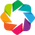

Loading BokehJS ...

CPU times: user 1.56 s, sys: 124 ms, total: 1.68 s
Wall time: 2.77 s


In [23]:
%%time

# ==========================================================
# 🧭 VISUALIZATION SETUP
# ==========================================================
### BOKEH
from bokeh.io import output_notebook
from bokeh.models import Label, HoverTool

### HOLOVIEWS
import holoviews as hv
from holoviews import opts
from holoviews.operation.datashader import rasterize, dynspread

### GEOVIEWS
import geoviews as gv
import geoviews.feature as gf
from cartopy import crs

### DATASHADER
import datashader as ds

### OTHERS
import time
import math
import numpy as np
import pandas as pd
import dask.array as da

# Enable Bokeh extensions inside the notebook
hv.extension('bokeh')
gv.extension('bokeh')
output_notebook()

## Magnitude Histogram

Here we build a parallel histogram of the magnitude column (MAG_AUTO_I_DERED), using Dask Array to compute the counts per bin in a distributed manner.

The result is an interactive and efficient histogram, which represents the distribution of the apparent brightness of the objects in the catalog.

In [24]:
%%time
# ==========================================================
# 📊 Parallel magnitude histogram with Dask + HoloViews
# ==========================================================
# Builds a distributed histogram of the magnitude column,
# summing only the counts per bin — without loading the entire column
# into memory. Ideal for massive data with millions of rows.

col_mag = "MAG_AUTO_I_DERED"

# ----------------------------------------------------------
# 🔹 Histogram parameters and limits
# ----------------------------------------------------------
# Manually sets the range and the number of bins.
# In real use, mag_min and mag_max can be computed in parallel
# using `.min().compute()` and `.max().compute()`.
num_bins = 50
mag_min = 10
mag_max = 30

# ----------------------------------------------------------
# 🔹 Column selection and type standardization
# ----------------------------------------------------------
# Converts the column to float64 with explicit meta
# and removes null values.
mag_values = (
    ddf[[col_mag]].map_partitions(
        lambda df: df.astype({col_mag: "float64"}),
        meta={col_mag: "f8"},
    )[col_mag]
    .dropna()
)

# `persist()` pins the graph and prevents Dask from rewriting or merging partitions
# after transformations, ensuring consistency in chunk sizes.
mag_values = mag_values.persist()

# ----------------------------------------------------------
# 🔹 Actual partition lengths
# ----------------------------------------------------------
# Extracts the size of each partition and stores it in a list.
# These values will be used to faithfully create the Dask Array.
lengths = mag_values.map_partitions(len).compute().tolist()

# ----------------------------------------------------------
# 🔹 Conversion to Dask Array
# ----------------------------------------------------------
# Creates a distributed Dask Array without materializing the data,
# keeping the chunked structure defined in `lengths`.
arr = mag_values.to_dask_array(lengths=lengths, optimize=False)

# ----------------------------------------------------------
# 🔹 Distributed histogram computation
# ----------------------------------------------------------
# `da.histogram` runs the computation in parallel per chunk,
# reducing the results by summing only small vectors (counts).
dcounts, bedges = da.histogram(arr, bins=num_bins, range=(mag_min, mag_max))

# Only the counts are computed; the edges are already NumPy arrays.
counts = dcounts.compute()
edges = bedges

# ----------------------------------------------------------
# 🔹 Visualization with HoloViews
# ----------------------------------------------------------
# Plots the final histogram. The X axis is limited to focus
# on the main magnitude range.
hist = hv.Histogram((edges, counts)).opts(
    title=f"Magnitude Distribution – {col_mag}",
    xlabel="Magnitude (i band)",
    ylabel="Number of objects",
    width=600, height=400,
    color="dodgerblue", line_color="black",
    xlim=(15, 28)
)

CPU times: user 49.1 ms, sys: 1.79 ms, total: 50.8 ms
Wall time: 132 ms


In [25]:
start = time.perf_counter()

In [26]:
# ----------------------------------------------------------
# 🔹 Final rendering
# ----------------------------------------------------------

hist

:Histogram   [x]   (Frequency)

In [27]:
end = time.perf_counter()
elapsed = end - start

minutes = int(elapsed // 60)
seconds = elapsed % 60

print(f"Execution time: {elapsed:.2f} segundos")
print(f"Or: {minutes} min {seconds:.2f} s")

Execution time: 1.44 segundos
Or: 0 min 1.44 s


## Color–color diagram

In this section, we create a color–color diagram (r−i vs g−r) using the COLOR_RI and COLOR_GR columns, calculated previously.

This type of plot is fundamental for photometric analyses, since it allows identifying patterns and separations of populations (stars, galaxies, quasars, etc.) based on the observed colors.

Rasterization via Datashader ensures performance even with millions of points.

In [28]:
%%time
# ==========================================================
# 🌈 Color–color diagram: COLOR_RI vs COLOR_GR
# ==========================================================
# Generates the color–color diagram (r−i vs g−r), widely used in astronomy
# to distinguish populations of stars, galaxies, and quasars.
# Each point represents an object with its photometric colors,
# and using Datashader makes it possible to render millions of points
# efficiently.

title = 'Color-Color Diagram – All Objects (r−i vs g−r)'
height = 500
width = 800
padding = 0.05

# ----------------------------------------------------------
# 🔹 Checking the required columns
# ----------------------------------------------------------
# Checks whether the COLOR_RI and COLOR_GR columns exist in the catalog,
# since they are essential to build the diagram.
cols_needed = ["COLOR_RI", "COLOR_GR"]
missing = [c for c in cols_needed if c not in ddf.columns]
if missing:
    raise ValueError(f"The required columns were not found: {missing}")

# Converts the columns to float64, removes null values, and persists in memory.
ddf_color = (
    ddf[cols_needed]
    .map_partitions(
        lambda df: df.astype({"COLOR_RI": "float64", "COLOR_GR": "float64"}),
        meta={"COLOR_RI": "f8", "COLOR_GR": "f8"},
    )
    .dropna()
    .persist()
)

# ----------------------------------------------------------
# 🔹 Conversion to HoloViews Points
# ----------------------------------------------------------
# Each point is defined by the colors (r−i, g−r).
# The Dask DataFrame is accepted directly, allowing lazy execution.
points_color = hv.Points(
    ddf_color,
    kdims=[("COLOR_RI", "r − i"), ("COLOR_GR", "g − r")]
)

# ----------------------------------------------------------
# 🔹 Rasterization with Datashader
# ----------------------------------------------------------
# Turns the points into a density image (count per pixel).
# Logarithmic normalization highlights both dense and sparse regions.
color_rasterized = rasterize(points_color, aggregator=ds.count()).opts(
    cmap="Viridis", cnorm='log',
    colorbar_opts={'title': 'Number of objects'}
)

# ----------------------------------------------------------
# 🔧 Hook: adjusting colorbar properties
# ----------------------------------------------------------
# The `colorbar_opts` parameter sets the title, but doesn't always apply
# the font size. The hook below accesses the rendered graphic object
# and ensures that the title and its font are configured correctly.
def _tweak_colorbar(plot, element):
    cb = plot.handles.get('colorbar')
    if cb is not None:
        cb.title = 'Number of objects'
        cb.title_text_font_size = '14pt'
        cb.title_standoff = 8

# ----------------------------------------------------------
# 🔹 Applying `dynspread()` and final rendering
# ----------------------------------------------------------
# `dynspread()` dynamically enlarges sparse pixels, improving readability
# without distorting the dense regions. The hook is applied after rendering
# to adjust the colorbar.
color_spread = dynspread(color_rasterized).opts(
    width=width, height=height, padding=padding, title=title,
    toolbar='above', colorbar=True,
    tools=['hover'],
    show_grid=True,
    xlim=(-10, 10), ylim=(-10, 10),
    hooks=[_tweak_colorbar]
)

CPU times: user 35.7 ms, sys: 3.75 ms, total: 39.5 ms
Wall time: 39.6 ms


In [29]:
start = time.perf_counter()

In [30]:
# ----------------------------------------------------------
# 🔹 Final rendering
# ----------------------------------------------------------
# The result is an interactive and scalable plot:
# - Shows the distribution of photometric colors;
# - Allows smooth zoom and pan;
# - Runs in a distributed fashion via Dask + Datashader.
color_spread

:DynamicMap   []
   :Image   [COLOR_RI,COLOR_GR]   (Count)

In [31]:
end = time.perf_counter()
elapsed = end - start

minutes = int(elapsed // 60)
seconds = elapsed % 60

print(f"Execution time: {elapsed:.2f} segundos")
print(f"Or: {minutes} min {seconds:.2f} s")

Execution time: 3.91 segundos
Or: 0 min 3.91 s


## Spatial Distribution

Finally, we visualize the spatial distribution of the objects on the sky, plotting RA × DEC with Plate Carrée and Mollweide projections.

These cartographic projections, implemented via **GeoViews + Cartopy**, allow interactively exploring the catalog's coverage, keeping the processing scalable and efficient in a Dask environment.

In [32]:
%%time

# ==========================================================
# 🔎 Checking the required columns (RA, DEC)
# ==========================================================
campos_necessarios = ["RA", "DEC"]
faltam = [c for c in campos_necessarios if c not in ddf.columns]
if faltam:
    raise ValueError(f"Missing columns for the spatial plot: {faltam}")

# ==========================================================
# 🌐 Selection and type conversion (avoids double[pyarrow])
# ==========================================================
ddf_pos = (
    ddf[campos_necessarios]
    .map_partitions(
        lambda df: df.astype({"RA": "float64", "DEC": "float64"}),
        meta={"RA": "f8", "DEC": "f8"},
    )
    .dropna()
    .persist()
)

# ==========================================================
# 🌐 Adjusting RA to the interval [-180, 180]
# ==========================================================
ddf_pos = ddf_pos.assign(RA_wrapped=((ddf_pos["RA"] + 180) % 360) - 180)

# ==========================================================
# 💠 Conversion to GeoViews Points
# ==========================================================
points = gv.Points(
    ddf_pos,
    kdims=[("RA_wrapped", "RA (degrees)"), ("DEC", "Dec (degrees)")]
)

CPU times: user 167 ms, sys: 2.09 ms, total: 169 ms
Wall time: 167 ms


### Plate Carrée Projection

Represents the sky in a flat projection (RA × Dec).

In [33]:
%%time
# ==========================================================
# 🗺️ Plate Carrée Projection
# ==========================================================
# Generates a density map of the objects in RA × Dec coordinates,
# using the "Plate Carrée" cartographic projection. This projection
# shows the sky as a simple rectangular grid, with RA (longitude)
# on the horizontal axis and Dec (latitude) on the vertical axis — ideal for
# visualizing wide distributions in astronomical catalogs.

title = 'Spatial Distribution – All Objects – Plate Carrée Projection'
height = 500
width = 1000
padding = 0.05

# ----------------------------------------------------------
# 🔹 Rasterization with Datashader
# ----------------------------------------------------------
# Converts the points into an aggregated image (count per pixel),
# reducing millions of points to an efficient visual representation.
# Logarithmic normalization (cnorm='log') highlights both dense regions
# and sparsely populated areas.
Plate_Carree_rasterized_points = rasterize(points, aggregator=ds.count()).opts(
    cmap="Viridis", cnorm='log'
)

# ----------------------------------------------------------
# 🔹 Custom RA ticks
# ----------------------------------------------------------
# RA (celestial longitude) increases to the left in astronomical maps.
# Here we define manual ticks and invert the X axis to keep this convention.
tick_positions = np.arange(180, -181, -30)   # 180, 150, 120, ..., -180
xticks = [(float(t), f"{int((t) % 360)}°") for t in tick_positions]

# ----------------------------------------------------------
# 🔧 Hook: adjusts colorbar properties
# ----------------------------------------------------------
# Ensures that the colorbar title and font size are applied
# correctly after rendering.
def _tweak_colorbar(plot, element):
    cb = plot.handles.get('colorbar')
    if cb is not None:
        cb.title = 'Number of objects'
        cb.title_text_font_size = '16pt'
        cb.title_standoff = 8

# ----------------------------------------------------------
# 🔹 Applying `dynspread()` and final rendering
# ----------------------------------------------------------
# `dynspread()` dynamically enlarges sparse pixels, improving
# the visibility of low-density regions without distorting the data.
# The `_tweak_colorbar` hook is applied at the end to adjust the colorbar.
Plate_Carree_spread_points = dynspread(Plate_Carree_rasterized_points).opts(
    width=width, height=height, padding=padding, title=title,
    toolbar='above', 
    colorbar=True, 
    tools=['hover'],
    show_grid=True,
    invert_xaxis=True,            # RA decreases to the left (astronomical convention)
    xlim=(-180, 180),             # Limits the X axis to the interval [-180, 180]
    xticks=xticks,                # Uses the manually defined ticks
    hooks=[_tweak_colorbar]       # Applies the hook to format the colorbar
).options(
    # Defines the geographic projection used to display the data
    opts.Image(projection=crs.PlateCarree())
)

CPU times: user 6.63 ms, sys: 964 μs, total: 7.59 ms
Wall time: 7.23 ms


In [34]:
start = time.perf_counter()

In [35]:
# ----------------------------------------------------------
# 🔹 Final rendering of the interactive map
# ----------------------------------------------------------
# The result is an interactive Bokeh/HoloViews map, where:
# - The colors represent the density of objects per pixel;
# - Zoom and pan are smooth even with large datasets;
# - The plot is fully compatible with distributed execution via Dask.
Plate_Carree_spread_points

:DynamicMap   []
   :Image   [RA_wrapped,DEC]   (Count)

In [36]:
end = time.perf_counter()
elapsed = end - start

minutes = int(elapsed // 60)
seconds = elapsed % 60

print(f"Execution time: {elapsed:.2f} segundos")
print(f"Or: {minutes} min {seconds:.2f} s")

Execution time: 3.69 segundos
Or: 0 min 3.69 s


### Mollweide Projection

Spherical visualization (entire sky), ideal for catalogs with wide coverage.

In [37]:
%%time
# ==========================================================
# 🌐 Mollweide Projection
# ==========================================================
# Projects the entire sky onto an ellipse (Mollweide projection),
# ideal for visualizing wide coverage of astronomical data.
# Datashader rasterization was already explained in the Plate Carrée section;
# here we highlight the use of labels, grid, and final composition.

title = 'Spatial Distribution – All Objects – Mollweide Projection'
height = 500
width = 1000
padding = 0.05

# ----------------------------------------------------------
# 🔹 Generating coordinate grids and labels (lon/lat)
# ----------------------------------------------------------
# Creates the longitude and latitude markers for the map.
# They will be used to position the text annotations on the plot.
longitudes = np.arange(30, 360, 30)
latitudes = np.arange(-75, 76, 15)

# Longitude labels (XX°), reversed to align with the inverted RA axis.
lon_labels = [f"{lon}°" for lon in longitudes]
lon_labels.reverse()

# Removes the 180° label (replaced by "Dec" on the side).
lon_labels = ["" if lbl == "180°" else lbl for lbl in lon_labels]

# Latitude labels (YY°) in standard ascending order.
lat_labels = [f"{lat}°" for lat in latitudes]

# Adds manual spacing to some latitude values
manual_spaces = {-15: 1, -30: 2, -45: 4, -60: 7, -75: 11}
lat_labels = [
    lbl + " " * manual_spaces.get(lat, 0) if lat < 0 else lbl
    for lbl, lat in zip(lat_labels, latitudes)
]


# ----------------------------------------------------------
# 🔹 Auxiliary DataFrame with label positions and texts
# ----------------------------------------------------------
# Combines longitude and latitude labels into a single DataFrame
# used by GeoViews to draw the annotations on the map.
labels_data = {
    "lon": list(np.flip(longitudes)) + [180] * len(latitudes),
    "lat": [0] * len(longitudes) + list(latitudes),
    "label": lon_labels + lat_labels,
}
df_labels = pd.DataFrame(labels_data)

# Visual configuration of the labels (size, color, alignment).
labels_plot = gv.Labels(df_labels, kdims=["lon", "lat"], vdims=["label"]).opts(
    text_font_size="12pt",
    text_color="black",
    text_align='right',
    text_baseline='bottom',
    projection=crs.Mollweide()
)

# ----------------------------------------------------------
# 🔹 Rasterization of the points in the Mollweide projection
# ----------------------------------------------------------
# Converts points into an aggregated image (count per pixel),
# with log normalization to handle large density variations.
Mollweide_rasterized_points = rasterize(points, aggregator=ds.count()).opts(
    cmap="Viridis", cnorm='log'
)

# ----------------------------------------------------------
# 🔧 Hook: adds the "RA" label in the footer
# ----------------------------------------------------------
# Inserts a fixed label below the plot in screen coordinates.
def _add_ra_footer(plot, element):
    fig = plot.state
    w = getattr(fig, "width", None) or getattr(fig, "outer_width", None) or width
    ra_label = Label(
        x=w/2, y=8,
        x_units='screen', y_units='screen',
        text='RA (degrees)',
        text_align='center',
        text_baseline='bottom',
        text_font_size='12pt'
    )
    fig.add_layout(ra_label)

# ----------------------------------------------------------
# 🔧 Hook: adds the "Dec" label on the left side
# ----------------------------------------------------------
# Inserts the label vertically at the center of the left edge.
def _add_dec_side(plot, element):
    fig = plot.state
    h = getattr(fig, "height", None) or getattr(fig, "outer_height", None) or height
    dec_label = Label(
        x=8, y=h/2,
        x_units='screen', y_units='screen',
        text='Dec (degrees)',
        text_align='center',
        text_baseline='middle',
        text_font_size='12pt',
        angle=math.pi/2
    )
    fig.add_layout(dec_label)

# ----------------------------------------------------------
# 🔧 Hook: adjusts the colorbar title and font
# ----------------------------------------------------------
# Ensures that the colorbar title and font size
# are applied correctly after rendering.
def _tweak_colorbar_moll(plot, element):
    cb = plot.handles.get('colorbar')
    if cb is not None:
        cb.title = 'Number of objects'
        cb.title_text_font_size = '16pt'
        cb.title_standoff = 8

# ----------------------------------------------------------
# 🔧 Hook: adds hover with only the object count per pixel
# ----------------------------------------------------------
# This is necessary because the geoviews projection changes the RA and Dec coordinates,
# so the traditional hover shows wrong RA and Dec values. Therefore,
# we omit the coordinates here, displaying only the counts.
def _hover_only_count(plot, element):
    # get/create the HoverTool
    h = None
    for t in plot.state.tools:
        if isinstance(t, HoverTool):
            h = t; break
    if h is None:
        h = HoverTool()
        plot.state.add_tools(h)

    # find out the name of the field with the pixel value
    src = plot.handles.get('source')
    val_field = 'image'
    if src is not None:
        for cand in ('z', 'image', 'Count', 'value'):
            if cand in src.data:
                val_field = cand
                break

    # tooltips: ONLY the count
    h.tooltips = [
        ("# objects", f"@{val_field}{{0}}"),
    ]
    h.point_policy = "follow_mouse"

# ----------------------------------------------------------
# 🔹 Applying `dynspread()` and composing the hooks
# ----------------------------------------------------------
# `dynspread()` highlights sparse regions, preserving data fidelity.
# The hooks add the axis labels and adjust the colorbar.
Mollweide_spread_points = dynspread(Mollweide_rasterized_points).opts(
    width=width, height=height, padding=padding, title=title,
    toolbar='above', 
    colorbar=True,
    invert_xaxis=True,
    hooks=[_tweak_colorbar_moll, _add_ra_footer, _add_dec_side, _hover_only_count]
).options(
    opts.Image(projection=crs.Mollweide())
)

# ----------------------------------------------------------
# 🔹 Coordinate grid
# ----------------------------------------------------------
# `gf.grid()` draws meridians and parallels on the projection.
grid = gf.grid()

CPU times: user 12.2 ms, sys: 50 μs, total: 12.3 ms
Wall time: 11.9 ms


In [38]:
start = time.perf_counter()

In [39]:
# ----------------------------------------------------------
# 🔹 Final rendering of the interactive map
# ----------------------------------------------------------
# In HoloViews/GeoViews, the `*` operator overlays layers:
#   (density image) * (grid) * (labels).

Mollweide_spread_points * grid * labels_plot

/scripts/nubia.garcia/LSST_LATAM/lsst_latam_env/lib/python3.12/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_graticules_30.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


:DynamicMap   []
   :Overlay
      .Image.I  :Image   [RA_wrapped,DEC]   (Count)
      .Grid.I   :Feature   [Longitude,Latitude]
      .Labels.I :Labels   [lon,lat]   (label)

In [40]:
end = time.perf_counter()
elapsed = end - start

minutes = int(elapsed // 60)
seconds = elapsed % 60

print(f"Execution time: {elapsed:.2f} segundos")
print(f"Or: {minutes} min {seconds:.2f} s")

Execution time: 2.97 segundos
Or: 0 min 2.97 s


# Closing Cluster and Client

In [41]:
cluster.close()
client.close()